In [ ]:
import matplotlib.pyplot as plt
import nanonis_spm
import numpy as np
from os.path import join
from scipy.optimize import curve_fit
import socket
import time

from prisma.file.io_lib import save_np_val
from prisma.physics_models.python import Ibeem_vector

In [ ]:
np.random.seed(0)

import jax
jax.config.update('jax_enable_x64', True)

In [ ]:
save_dir = 'Beem_Data\\Nanonis_Test_9'

In [4]:
connection = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
connection.connect(("localhost",6502))
nanonisInstance = nanonis_spm.Nanonis(connection)

In [5]:
nanonisInstance.returnDebugInfo(1)

In [6]:
Spectr_Channels=[1, 24]
time.sleep(1)
nanonisInstance.BiasSpectr_Open()
nanonisInstance.BiasSpectr_ChsSet(Spectr_Channels)

Send message: 
bytearray(b'BiasSpectr.Open\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x01\x00\x00')
BodySize: 8
Received Body: 8
BodySize2: 8
Received Body2: 8
Received data:
b'BiasSpectr.Open\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x00\x00\x00'
b'\x00\x00\x00\x00\x00\x00\x00\x00'
Correct Command.
No error messages. Error status was: 0
Send message: 
bytearray(b'BiasSpectr.ChsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0c\x00\x01\x00\x00\x00\x00\x00\x02\x00\x00\x00\x01\x00\x00\x00\x18')
BodySize: 8
Received Body: 8
BodySize2: 8
Received Body2: 8
Received data:
b'BiasSpectr.ChsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x00\x00\x00'
b'\x00\x00\x00\x00\x00\x00\x00\x00'
Correct Command.
No error messages. Error status was: 0


('', b'\x00\x00\x00\x00\x00\x00\x00\x00', [])

In [ ]:
x0 = 1.25
xf = 0.4
nanonisInstance.Bias_Set(x0)
nanonisInstance.BiasSpectr_LimitsSet(np.array(x0),
                                     np.array(xf))

Send message: 
bytearray(b'BiasSpectr.LimitsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x01\x00\x00?\xa0\x00\x00>\xcc\xcc\xcd')
BodySize: 8
Received Body: 8
BodySize2: 8
Received Body2: 8
Received data:
b'BiasSpectr.LimitsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x00\x00\x00'
b'\x00\x00\x00\x00\x00\x00\x00\x00'
Correct Command.
No error messages. Error status was: 0


('', b'\x00\x00\x00\x00\x00\x00\x00\x00', [])

In [8]:
Spectr_AcquiredData=nanonisInstance.BiasSpectr_Start(1,"Example_BiasSpectroscopy")[2][5]

Send message: 
bytearray(b'BiasSpectr.Start\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00 \x00\x01\x00\x00\x00\x00\x00\x01\x00\x00\x00\x18Example_BiasSpectroscopy')
BodySize: 508
Received Body: 508
BodySize2: 508
Received Body2: 508
Received data:
b'BiasSpectr.Start\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x01\xfc\x00\x00\x00\x00'
b"\x00\x00\x00,\x00\x00\x00\x03\x00\x00\x00\rBias calc (V)\x00\x00\x00\x0bInput 2 (V)\x00\x00\x00\x08Bias (V)\x00\x00\x00\x03\x00\x00\x00!?\xa0\x00\x00?\x9c\x99\x9a?\x9933?\x95\xcc\xcd?\x92ff?\x8f\x00\x00?\x8b\x99\x9a?\x8833?\x84\xcc\xcd?\x81ff?|\x00\x00?u33?nff?g\x99\x9a?`\xcc\xcc?Z\x00\x00?S33?Lff?E\x99\x9a?>\xcc\xcd?8\x00\x00?133?*ff?#\x99\x99?\x1c\xcc\xcc?\x16\x00\x00?\x0f33?\x08ff?\x01\x99\x99>\xf5\x99\x98>\xe8\x00\x00>\xdaff>\xcc\xcc\xcc\xbd\x90\xaa2\xbd\x8a\xb1\xa1\xbd\x8b\x15,\xbd\x86\x17!\xbd\x81|\xd0\xbdu,\x89\xbdp\x05\x00\xbdl#U\xbda\xe6P\xbdU\xf4\xc3\xbdI\x1a\x89\xbdG\xe3B\xbd?\xc1\xad\x

In [9]:
# %timeit nanonisInstance.BiasSpectr_Start(1,"Example_BiasSpectroscopy")[2][5]

In [10]:
AcqSignal_Current=Spectr_AcquiredData[1]

In [ ]:
save_np_val(save_dir, "AcqSignal_Current.npy", AcqSignal_Current)

In [12]:
AcqSignal_Bias=Spectr_AcquiredData[0]

In [ ]:
save_np_val(save_dir, "AcqSignal_Bias.npy", AcqSignal_Bias)

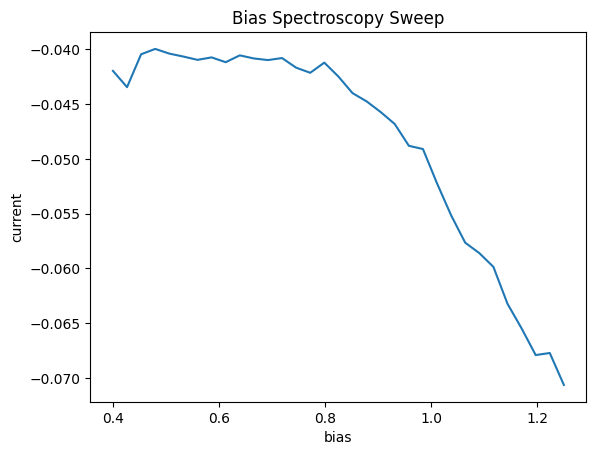

In [14]:
plt.plot(AcqSignal_Bias, AcqSignal_Current)
plt.title("Bias Spectroscopy Sweep")
plt.xlabel("bias")
plt.ylabel("current");

In [ ]:
model_f = Ibeem_vector
model_name = "Ibeem"
p0_cf = [.04, .8, 1.]

In [18]:
w_opt, w_cov = curve_fit(model_f, AcqSignal_Bias, -1 * AcqSignal_Current,
                         p0=p0_cf, absolute_sigma=False)

In [19]:
w_opt

array([4.12057000e-02, 8.50363616e-01, 7.35050247e-06])

In [ ]:
save_np_val(save_dir, f"w_opt_{model_name}.npy", w_opt)

In [21]:
w_cov

array([[4.93228697e-08, 8.32261647e-07, 4.13799053e-12],
       [8.32261647e-07, 6.34486012e-05, 1.38913243e-09],
       [4.13799053e-12, 1.38913243e-09, 4.47583704e-14]])

In [22]:
np.sqrt(w_cov[1, 1])

np.float64(0.007965463022797447)

In [ ]:
save_np_val(save_dir, f"w_cov_{model_name}.npy", w_cov)

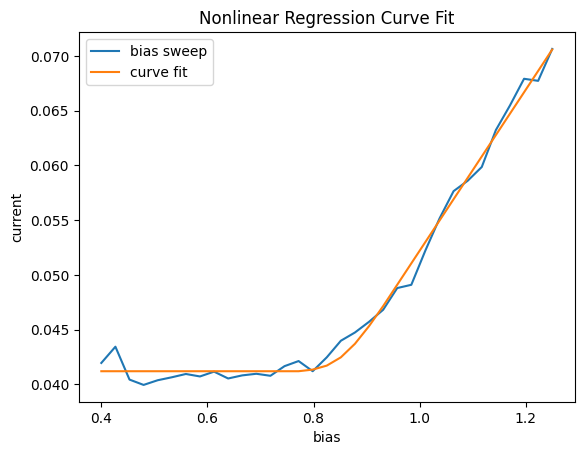

In [24]:
plt.plot(AcqSignal_Bias, -1 * AcqSignal_Current)
plt.plot(AcqSignal_Bias, model_f(AcqSignal_Bias, w_opt[0], w_opt[1], w_opt[2]))
plt.title("Nonlinear Regression Curve Fit")
plt.xlabel("bias")
plt.ylabel("current")
plt.legend(["bias sweep", "curve fit"]);

In [25]:
spectr_sample_ct = 100

In [26]:
nanonisInstance.BiasSpectr_LimitsSet(np.array(x0),
                                     np.array(xf))

Send message: 
bytearray(b'BiasSpectr.LimitsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x01\x00\x00?\xa0\x00\x00>\xcc\xcc\xcd')
BodySize: 8
Received Body: 8
BodySize2: 8
Received Body2: 8
Received data:
b'BiasSpectr.LimitsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x00\x00\x00'
b'\x00\x00\x00\x00\x00\x00\x00\x00'
Correct Command.
No error messages. Error status was: 0


('', b'\x00\x00\x00\x00\x00\x00\x00\x00', [])

In [27]:
spectr_bias_series = []
spectr_current_series = []
for _ in range(spectr_sample_ct):
    spectr_acq = nanonisInstance.BiasSpectr_Start(1,"Example_BiasSpectroscopy")[2][5]
    current_acq = spectr_acq[1]
    bias_acq = spectr_acq[2]
    spectr_bias_series.append(bias_acq)
    spectr_current_series.append(current_acq)
spectr_bias_series_np = np.empty((spectr_sample_ct, len(spectr_bias_series[0])))
spectr_current_series_np = np.empty((spectr_sample_ct, len(spectr_current_series[0])))
for i in range(spectr_sample_ct):
    spectr_bias_series_np[i] = spectr_bias_series[i]
    spectr_current_series_np[i] = spectr_current_series[i]
save_np_val(save_dir, "spectr_bias_series.npy", spectr_bias_series_np)
save_np_val(save_dir, "spectr_current_series.npy", spectr_current_series_np)


Send message: 
bytearray(b'BiasSpectr.Start\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00 \x00\x01\x00\x00\x00\x00\x00\x01\x00\x00\x00\x18Example_BiasSpectroscopy')
BodySize: 508
Received Body: 508
BodySize2: 508
Received Body2: 508
Received data:
b'BiasSpectr.Start\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x01\xfc\x00\x00\x00\x00'
b'\x00\x00\x00,\x00\x00\x00\x03\x00\x00\x00\rBias calc (V)\x00\x00\x00\x0bInput 2 (V)\x00\x00\x00\x08Bias (V)\x00\x00\x00\x03\x00\x00\x00!?\xa0\x00\x00?\x9c\x99\x9a?\x9933?\x95\xcc\xcd?\x92ff?\x8f\x00\x00?\x8b\x99\x9a?\x8833?\x84\xcc\xcd?\x81ff?|\x00\x00?u33?nff?g\x99\x9a?`\xcc\xcc?Z\x00\x00?S33?Lff?E\x99\x9a?>\xcc\xcd?8\x00\x00?133?*ff?#\x99\x99?\x1c\xcc\xcc?\x16\x00\x00?\x0f33?\x08ff?\x01\x99\x99>\xf5\x99\x98>\xe8\x00\x00>\xdaff>\xcc\xcc\xcc\xbd\x89\x0fj\xbd\x81\xe7\xf9\xbdxDa\xbdv\x98c\xbdm\x7f\x02\xbdc#,\xbd\\5\x0e\xbdVSw\xbdG\x18l\xbd8\x85\xf9\xbd8d\xf8\xbd)\xf2"\xbd)\xc9\xa6\xbd \x13n\xbd\x15\

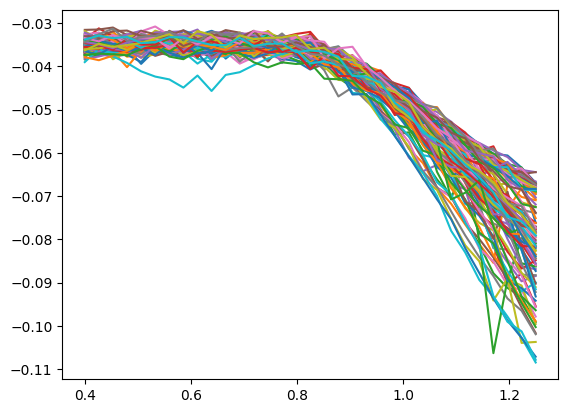

In [28]:
for i in range(spectr_sample_ct):
    # plt.figure()
    plt.plot(spectr_bias_series_np[i], spectr_current_series_np[i])

In [29]:
param_ct = 3

In [30]:
w_opt_series_np = np.empty((spectr_sample_ct, param_ct))
w_cov_series_np = np.empty((spectr_sample_ct, param_ct, param_ct))
for i in range(spectr_sample_ct):
    w_opt_i, w_cov_i = curve_fit(model_f, spectr_bias_series_np[i], -1 * spectr_current_series_np[i],
                                 p0=p0_cf, absolute_sigma=False)
    w_opt_series_np[i] = w_opt_i
    w_cov_series_np[i] = w_cov_i
save_np_val(save_dir, f"w_opt_series_{model_name}.npy", w_opt_series_np)
save_np_val(save_dir, f"w_cov_Ibeem_series_{model_name}.npy", w_cov_series_np)

In [31]:
w_opt_avg = np.mean(w_opt_series_np, axis=0)
w_opt_avg

array([3.54596570e-02, 8.73992273e-01, 1.19475204e-05])

In [32]:
w_opt_series_np[:, 1]

array([0.8656006 , 0.86173517, 0.8584708 , 0.85650365, 0.84360386,
       0.84338874, 0.84966252, 0.83840192, 0.86672362, 0.86873758,
       0.87105167, 0.86931943, 0.84826773, 0.86953963, 0.82850084,
       0.84751463, 0.85208853, 0.83589042, 0.86301417, 0.87198258,
       0.8591799 , 0.85241121, 0.84506204, 0.84971135, 0.84793246,
       0.84295671, 0.86851266, 0.840244  , 0.85175746, 0.85293437,
       0.85672821, 0.79989647, 0.88192075, 0.93147067, 0.85342425,
       0.8792526 , 0.86708963, 0.85805496, 0.87156269, 0.87606668,
       0.87430322, 0.90159155, 0.8989462 , 0.93527125, 0.91881847,
       0.92559562, 0.89624487, 0.91278535, 0.86411177, 0.90949092,
       0.87485013, 0.88262325, 0.90504163, 0.88393805, 0.90915978,
       0.8747859 , 0.89573512, 0.88931544, 0.90974229, 0.89855635,
       0.90172579, 0.90372091, 0.91212535, 0.88809661, 0.88614064,
       0.8553304 , 0.91014988, 0.8983935 , 0.90190694, 0.91494235,
       0.89924608, 0.87011905, 0.87215413, 0.88504659, 0.86471

In [33]:
w_opt_stddev = np.std(w_opt_series_np, axis=0)
w_opt_stddev

array([1.18193029e-03, 2.50906684e-02, 3.34274980e-06])

In [34]:
w_cov_mean = np.mean(np.sqrt(w_cov_series_np), axis=0)
w_cov_mean

array([[3.55921328e-04, 1.16480205e-03, 3.61290885e-06],
       [1.16480205e-03, 8.49430727e-03, 5.21391177e-05],
       [3.61290885e-06, 5.21391177e-05, 3.94222052e-07]])

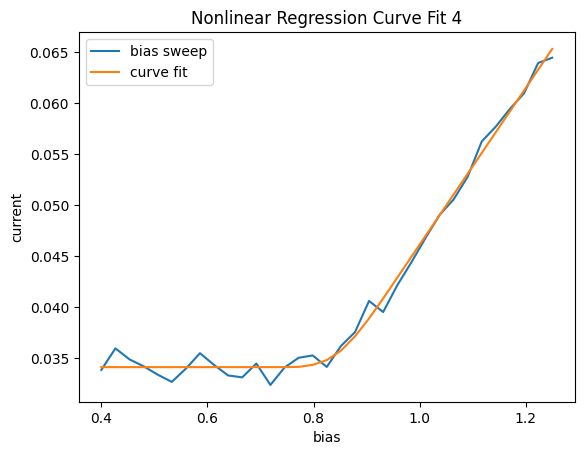

In [35]:
fit_i = 4
bias_i = spectr_bias_series_np[fit_i]
current_i = spectr_current_series_np[fit_i]
w_opt_i = w_opt_series_np[fit_i]
plt.plot(bias_i, -1 * current_i)
plt.plot(bias_i, model_f(bias_i, w_opt_i[0], w_opt_i[1], w_opt_i[2]))
plt.title(f"Nonlinear Regression Curve Fit {fit_i}")
plt.xlabel("bias")
plt.ylabel("current")
plt.legend(["bias sweep", "curve fit"]);

In [36]:
nanonisInstance.close()

# Bias Scramble

In [37]:
bias_scramble = np.random.uniform(x0, xf, 30)
bias_scramble

array([0.44976315, 1.23660711, 0.51171907, 1.12120266, 0.6272382 ,
       0.56074314, 1.05575372, 0.96133284, 0.83768293, 0.496696  ,
       0.54548129, 0.82019715, 0.83894621, 1.06189885, 0.85717712,
       0.48685543, 0.90494946, 0.40784146, 1.1693828 , 0.87555733,
       0.56504414, 0.99144539, 0.80328748, 1.1534669 , 0.82618575,
       0.66380077, 0.93075057, 1.06060439, 0.85521263, 0.42584411])

In [38]:
eps = np.array(1e-3, dtype=np.float32)

In [39]:
data_BiasSpectr = []
current_BiasSpectr = []
for b in bias_scramble:
    nanonisInstance.BiasSpectr_LimitsSet(np.array(b-eps),
                                         np.array(b+eps))
    data_eps=nanonisInstance.BiasSpectr_Start(1,"Example_BiasSpectroscopy")[2][5]
    current_eps=data_eps[1]
    bias_eps=data_eps[2]
    data_BiasSpectr.append((current_eps, bias_eps))
    current_BiasSpectr.append(np.mean(current_eps))

Send message: 
bytearray(b'BiasSpectr.LimitsSet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x01\x00\x00>\xe5\xc4H>\xe6\xcam')


OSError: [WinError 10038] An operation was attempted on something that is not a socket

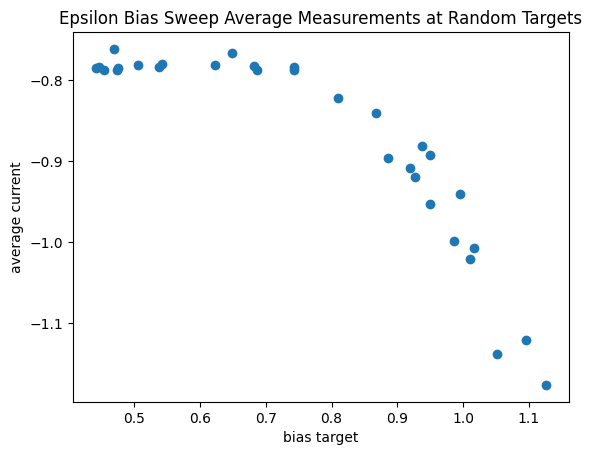

In [ ]:
plt.scatter(bias_scramble, current_BiasSpectr)
plt.title("Epsilon Bias Sweep Average Measurements at Random Targets")
plt.xlabel("bias target")
plt.ylabel("average current");

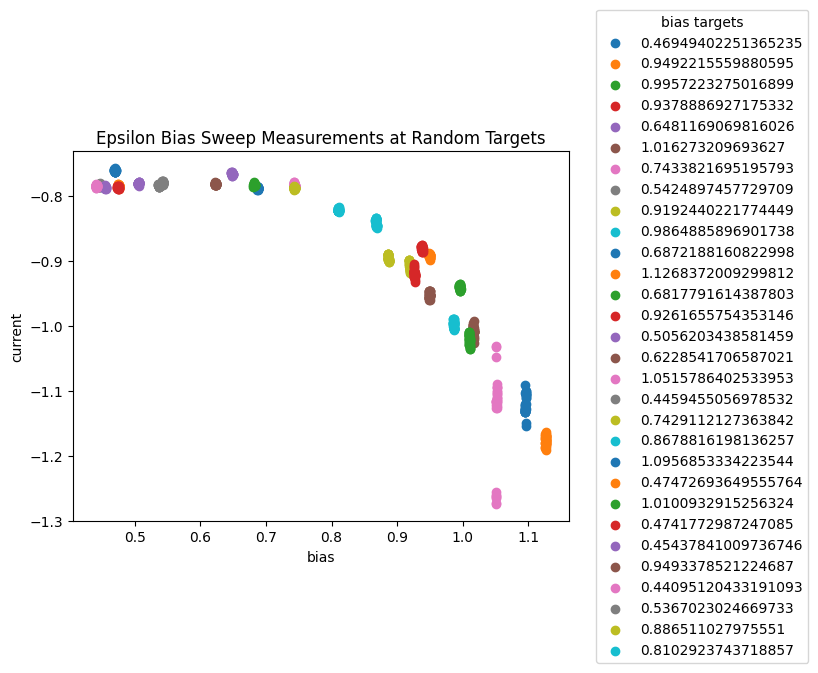

In [ ]:
for i in range(len(data_BiasSpectr)):
    plt.scatter(data_BiasSpectr[i][1], data_BiasSpectr[i][0])
plt.title("Epsilon Bias Sweep Measurements at Random Targets")
plt.xlabel("bias")
plt.ylabel("current")
plt.legend(bias_scramble,
           bbox_to_anchor=(1.04, .5), loc="center left",
           title="bias targets");

In [ ]:
# for i in range(len(data_BiasSpectr)):
#     plt.figure(figsize=(10, 4))
#     plt.scatter(data_BiasSpectr[i][1], data_BiasSpectr[i][0])
#     plt.title(f"bias target: {bias_scramble[i]}")
#     plt.xlabel("bias")
#     plt.ylabel("current");

In [ ]:
# for i in range(len(data_BiasSpectr)):
#     print(f"bias target: {bias_scramble[i]}")
#     print(f"bias measurement: {data_BiasSpectr[i][1]}")
#     print(f"current measurement: {data_BiasSpectr[i][0]}")

In [ ]:
data_ValGet = []
for b in bias_scramble:
    nanonisInstance.Bias_Set(b)
    bias_val = nanonisInstance.Signals_ValGet(24, True)[2]
    current_val = nanonisInstance.Signals_ValGet(1, True)[2]
    data_ValGet.append((current_val, bias_val))

Send message: 
bytearray(b'Bias.Set\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x04\x00\x01\x00\x00>\xf0a\x85')
BodySize: 8
Received Body: 8
BodySize2: 8
Received Body2: 8
Received data:
b'Bias.Set\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x00\x00\x00'
b'\x00\x00\x00\x00\x00\x00\x00\x00'
Correct Command.
No error messages. Error status was: 0
Send message: 
bytearray(b'Signals.ValGet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x08\x00\x01\x00\x00\x00\x00\x00\x18\x00\x00\x00\x01')
BodySize: 12
Received Body: 12
BodySize2: 12
Received Body2: 12
Received data:
b'Signals.ValGet\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0c\x00\x00\x00\x00'
b'?\x04\x94D\x00\x00\x00\x00\x00\x00\x00\x00'
Correct Command.
No error messages. Error status was: 0
f: 0.5178873538970947
Send message

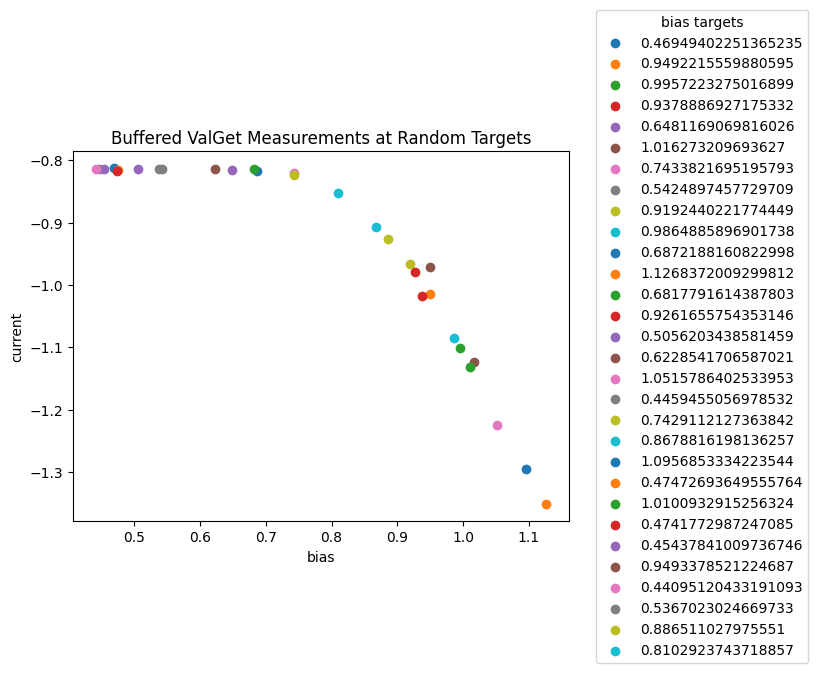

In [ ]:
for i in range(len(data_ValGet)):
    plt.scatter(bias_scramble[i], data_ValGet[i][0])
plt.title("Buffered ValGet Measurements at Random Targets")
plt.xlabel("bias")
plt.ylabel("current")
plt.legend(bias_scramble,
           bbox_to_anchor=(1.04, .5), loc="center left",
           title="bias targets");

In [ ]:
# for i in range(len(data_ValGet)):
#     print(f"bias target: {bias_scramble[i]}")
#     print(f"bias measurement: {data_ValGet[i][1]}")
#     print(f"current measurement: {data_ValGet[i][0]}")

bias target: 0.46949402251365235
bias measurement: [0.8102923631668091]
current measurement: [-0.8409247398376465]
bias target: 0.9492215559880595
bias measurement: [0.8102923631668091]
current measurement: [-0.8657147884368896]
bias target: 0.9957223275016899
bias measurement: [0.8102923631668091]
current measurement: [-0.8703873753547668]
bias target: 0.9378886927175332
bias measurement: [0.8102923631668091]
current measurement: [-0.8552677631378174]
bias target: 0.6481169069816026
bias measurement: [0.8102923631668091]
current measurement: [-0.837822437286377]
bias target: 1.016273209693627
bias measurement: [0.8102923631668091]
current measurement: [-0.8393404483795166]
bias target: 0.7433821695195793
bias measurement: [0.8102923631668091]
current measurement: [-0.8651020526885986]
bias target: 0.5424897457729709
bias measurement: [0.8102923631668091]
current measurement: [-0.8497815132141113]
bias target: 0.9192440221774449
bias measurement: [0.8102923631668091]
current measuremen